# Modelos de clasificación
## Data Mining - Doctorado UDP 2026
**Dr. Bastián González-Bustamante, Profesor Asociado** \
Octubre 2026

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Doctorado-UDP/data-mining-2026/blob/main/code/1_modelos_clasificacion.ipynb)

**Sesión 8 · jueves 15 de octubre de 2026 · Parte 2: demostración.**

Este notebook aplica los siete modelos de la presentación a un mismo problema: clasificar grupos de bloques censales de California en **5 clases de valor de la vivienda**. Cada sección corresponde a una sección de la presentación:

| N.º | Sección | Presentación |
|---|---|---|
| 1–2 | Datos, variable objetivo y línea base | Repaso S6–S7 |
| 3 | Regresión logística | Regresión logística |
| 4 | Naive Bayes | Naive Bayes |
| 5 | k-NN | k-vecinos más cercanos |
| 6 | SVM | Máquinas de vectores de soporte |
| 7 | MLP | Redes neuronales |
| 8 | Random forest | Random forest |
| 9 | XGBoost | XGBoost |
| 10–11 | Comparación y fronteras de decisión | Comparativa de los modelos |
| 12 | Ejercicios | No aplica |

**Cómo usarlo.**
- Las celdas precedidas por **▶ En vivo** se ejecutan durante la clase. El resto queda para la revisión autónoma.
- Todo el notebook corre de principio a fin en la CPU de un computador portátil en menos de 10 minutos. Para lograrlo, el SVM se ajusta sobre una submuestra del conjunto de entrenamiento y las grillas de hiperparámetros son pequeñas; cada sección lo indica.
- Las versiones de las librerías están fijadas en el archivo `requirements.txt` del repositorio del curso. En Google Colab se usan las versiones preinstaladas (ver "Entorno", abajo).
- `random_state=86` en todos los pasos aleatorios, para que los resultados sean reproducibles.

### Entorno: local o Google Colab

Este notebook corre en su computador y en Google Colab. La primera celda de código detecta dónde se ejecuta:
- **En Google Colab** instala solo los paquetes que falten (en esta sesión, ninguno), sin actualizar los preinstalados, así que no hace falta reiniciar la sesión. Los datos se descargan de fuentes públicas. Para conservar sus cambios, use "Archivo → Guardar una copia en Drive".
- **En su computador** no instala nada: cree antes un entorno virtual con `pip install -r requirements.txt`.

Luego muestra las versiones instaladas y verifica que estén en el rango soportado: Python ≥ 3.11, scikit-learn ≥ 1.6, pandas ≥ 2.2 y NumPy ≥ 2.0. Con versiones distintas de las de `requirements.txt`, algunos resultados pueden cambiar levemente.

In [1]:
## Entorno: detectar Google Colab, instalar solo lo que falte y verificar las versiones
import re
import sys
from importlib import invalidate_caches
from importlib.metadata import version
from importlib.util import find_spec

## Paquetes que usa este notebook: {módulo: (nombre en pip, versión mínima soportada)}
PAQUETES = {
    "sklearn": ("scikit-learn", "1.6"),
    "pandas": ("pandas", "2.2"),
    "numpy": ("numpy", "2.0"),
    "matplotlib": ("matplotlib", "3.9"),
    "xgboost": ("xgboost", "2.1"),
}

EN_COLAB = "google.colab" in sys.modules
faltan = [pip for modulo, (pip, _) in PAQUETES.items() if find_spec(modulo) is None]
if faltan and EN_COLAB:
    ## En Colab se instalan solo los paquetes que faltan; los preinstalados no se actualizan
    get_ipython().run_line_magic("pip", "install -q " + " ".join(faltan))
    invalidate_caches()
    faltan = []
## En su computador no se instala nada: el entorno virtual se crea con requirements.txt
assert not faltan, f"Faltan paquetes: {', '.join(faltan)}. Instálelos con pip install -r requirements.txt."


def version_al_menos(paquete, minima):
    ## Compara los dos primeros números de la versión instalada con la mínima (p. ej., "1.6.1" >= "1.6")
    actual = tuple(int(n) for n in re.findall(r"\d+", version(paquete))[:2])
    return actual >= tuple(int(n) for n in minima.split("."))


print(f"Python {sys.version.split()[0]} | "
      + " | ".join(f"{pip} {version(pip)}" for pip, _ in PAQUETES.values())
      + (" | Google Colab" if EN_COLAB else " | computador local"))
assert sys.version_info >= (3, 11), "Este notebook requiere Python 3.11 o superior."
antiguos = [f"{pip} {version(pip)} (mínimo {minima})" for pip, minima in PAQUETES.values()
            if not version_al_menos(pip, minima)]
assert not antiguos, f"Versiones no soportadas: {'; '.join(antiguos)}. Actualice esos paquetes en su entorno."

Python 3.12.7 | scikit-learn 1.9.1 | pandas 3.0.6 | numpy 2.5.4 | matplotlib 3.11.2 | xgboost 3.4.1 | computador local


In [2]:
## Importar librerías necesarias
import inspect
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

import sklearn
import xgboost as xgb
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import DecisionBoundaryDisplay, permutation_importance
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
)

## Versiones (en su computador, las de requirements.txt; en Colab, las preinstaladas)
print(f"pandas {pd.__version__} | numpy {np.__version__} | scikit-learn {sklearn.__version__} | xgboost {xgb.__version__}")

pandas 3.0.6 | numpy 2.5.4 | scikit-learn 1.9.1 | xgboost 3.4.1


In [3]:
## Estilo de los gráficos: fondo claro, ejes discretos, grilla tenue
plt.rcParams.update({
    "figure.dpi": 100,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
})

## Colores: dos series categóricas y una rampa secuencial (azules) para las 5 clases ordenadas
AZUL, NARANJA, VERDE = "#2a78d6", "#eb6834", "#1baf7a"
RAMPA_CLASES = ["#cde2fb", "#86b6ef", "#2a78d6", "#1c5cab", "#0d366b"]

## 1. Datos: California Housing

**▶ En vivo.** Usamos el conjunto *California Housing*, incluido en scikit-learn (la primera vez se descarga desde la fuente pública que usa scikit-learn y luego queda en caché). Proviene del censo de EE. UU. de 1990 (Pace y Barry, 1997, *Statistics & Probability Letters*, 33(3), 291–297). Cada fila es un **grupo de bloques censales** (*block group*), la unidad geográfica más pequeña para la que se publican datos muestrales; hay 20.640 filas y 8 predictores:

| Variable | Descripción |
|---|---|
| `MedInc` | Ingreso mediano de los hogares (decenas de miles de USD) |
| `HouseAge` | Antigüedad mediana de las viviendas (años) |
| `AveRooms` | Promedio de habitaciones por hogar |
| `AveBedrms` | Promedio de dormitorios por hogar |
| `Population` | Población del grupo de bloques |
| `AveOccup` | Promedio de ocupantes por hogar |
| `Latitude` | Latitud |
| `Longitude` | Longitud |

La variable objetivo, `MedHouseVal`, es el valor mediano de la vivienda en cientos de miles de USD (con tope en 5,0). El ángulo de política pública es la asequibilidad de la vivienda; el ángulo de ingeniería son los predictores continuos y espaciales.

In [4]:
## Cargar el dataset como DataFrame (descarga pública de scikit-learn, sin rutas locales)
california = fetch_california_housing(as_frame=True)
X = california.data                 ## 8 predictores
y = california.target               ## MedHouseVal (cientos de miles de USD)
print(X.shape)
X.head()

(20640, 8)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


In [5]:
## Estadísticos descriptivos: nótense las escalas muy distintas (Population vs AveBedrms)
X.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.87,1.90,0.50,2.56,3.53,4.74,15.00
HouseAge,20640.0,28.64,12.59,1.00,18.00,29.00,37.00,52.00
AveRooms,20640.0,5.43,2.47,0.85,4.44,5.23,6.05,141.91
AveBedrms,20640.0,1.10,0.47,0.33,1.01,1.05,1.10,34.07
Population,20640.0,1425.48,1132.46,3.00,787.00,1166.00,1725.00,35682.00
AveOccup,20640.0,3.07,10.39,0.69,2.43,2.82,3.28,1243.33
Latitude,20640.0,35.63,2.14,32.54,33.93,34.26,37.71,41.95
Longitude,20640.0,-119.57,2.00,-124.35,-121.80,-118.49,-118.01,-114.31


### 1.1 División 70/15/15

**▶ En vivo.** Separamos tres conjuntos:
- **Entrenamiento (70%)**: ajusta los modelos.
- **Validación (15%)**: compara modelos y elige hiperparámetros.
- **Prueba (15%)**: se usa **una sola vez**, al final, con el modelo elegido (sección 10).

In [6]:
## Primero separamos 70% de entrenamiento y 30% restante
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=86)
## El 30% restante se divide en dos mitades: validación (15%) y prueba (15%)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=86)

print(f"Entrenamiento: {len(X_train):,} | Validación: {len(X_val):,} | Prueba: {len(X_test):,}")

Entrenamiento: 14,448 | Validación: 3,096 | Prueba: 3,096


### 1.2 Variable objetivo: quintiles aprendidos en entrenamiento

**▶ En vivo.** Convertimos `MedHouseVal` en 5 clases ordenadas (`Low`, `Medium-Low`, `Medium`, `Medium-High`, `High`) usando sus **quintiles**. Los cortes se calculan **solo con los datos de entrenamiento** (`pd.qcut(..., retbins=True)`) y luego se aplican a validación y prueba con `pd.cut`. Los bordes externos se reemplazan por −∞ y +∞, para que un valor de validación o prueba fuera del rango observado en entrenamiento igual reciba clase.

Calcular los cortes con todos los datos sería una **fuga de información** (*data leakage*): los conjuntos de validación y prueba influirían en la definición de la variable que queremos predecir.

Este formato es el mismo del **desafío de predicción 2026** (lanzamiento en S11): 5 clases, cortes aprendidos en entrenamiento y **macro F1** como métrica. Aquí lo ensayamos con otro conjunto de datos; el del desafío se presentará en S11.

In [7]:
## Etiquetas ordenadas de las 5 clases
etiquetas = ["Low", "Medium-Low", "Medium", "Medium-High", "High"]

## Cortes (bins) aprendidos SOLO en entrenamiento
y_train_cat, cortes = pd.qcut(y_train, q=5, labels=etiquetas, retbins=True)

## Bordes externos abiertos: -inf y +inf
cortes_ext = cortes.copy()
cortes_ext[0], cortes_ext[-1] = -np.inf, np.inf

## Aplicar los mismos cortes a validación y prueba
y_val_cat = pd.cut(y_val, bins=cortes_ext, labels=etiquetas)
y_test_cat = pd.cut(y_test, bins=cortes_ext, labels=etiquetas)

## Códigos enteros 0-4 (XGBoost exige clases enteras consecutivas)
y_train_c = y_train_cat.cat.codes.to_numpy()
y_val_c = y_val_cat.cat.codes.to_numpy()
y_test_c = y_test_cat.cat.codes.to_numpy()

print("Cortes internos (cientos de miles de USD):", np.round(cortes[1:-1], 3))
print("Valores sin clase en validación/prueba:", int(y_val_cat.isna().sum() + y_test_cat.isna().sum()))

Cortes internos (cientos de miles de USD): [1.079 1.575 2.092 2.89 ]
Valores sin clase en validación/prueba: 0


In [8]:
## Distribución de clases: exactamente 20% en entrenamiento, aproximadamente 20% en validación y prueba
distribucion = pd.DataFrame({
    "Entrenamiento": y_train_cat.value_counts(normalize=True, sort=False),
    "Validación": y_val_cat.value_counts(normalize=True, sort=False),
    "Prueba": y_test_cat.value_counts(normalize=True, sort=False),
})
distribucion.round(3)

,Entrenamiento,Validación,Prueba
MedHouseVal,,,
Low,0.2,0.209,0.205
Medium-Low,0.2,0.198,0.194
Medium,0.2,0.195,0.196
Medium-High,0.2,0.194,0.198
High,0.2,0.204,0.206


## 2. Línea base y métrica

**▶ En vivo.** Antes de cualquier modelo, fijamos una **línea base** (*baseline*) con `DummyClassifier`, que ignora los predictores:
- `most_frequent`: predice siempre la clase más frecuente en entrenamiento.
- `stratified`: predice al azar respetando las proporciones de entrenamiento.

Un modelo que no supera esta línea base no ha aprendido nada útil.

**¿Por qué macro F1 y no accuracy?** El macro F1 es el promedio simple del F1 de cada clase:

$$\text{F1}_{\text{macro}} = \frac{1}{K}\sum_{k=1}^{K} \text{F1}_k, \qquad \text{F1}_k = \frac{2\,\text{Precision}_k\,\text{Recall}_k}{\text{Precision}_k + \text{Recall}_k}$$

- Da **el mismo peso a cada clase**: un modelo que ignora una clase (por ejemplo, `Low`, la más relevante para una política de vivienda asequible) recibe F1 = 0 en esa clase y lo paga en el promedio.
- La accuracy puede ser alta aunque el modelo ignore una clase minoritaria. Aquí las clases están balanceadas por construcción, pero en otros problemas (y en validación y prueba, donde no son exactamente 20%) esa diferencia importa.
- Es la métrica del desafío de predicción.

Una limitación: el F1 no considera el orden de las clases. Confundir `High` con `Low` cuesta lo mismo que confundirla con `Medium-High`. Volveremos a las métricas en S9.

In [9]:
## Diccionarios para guardar resultados y modelos ajustados
resultados = {}
modelos = {}


def evaluar(nombre, modelo, X_tr=None, y_tr=None, **fit_kwargs):
    ## Ajusta el modelo en entrenamiento, mide el tiempo y calcula métricas en validación
    X_tr = X_train if X_tr is None else X_tr
    y_tr = y_train_c if y_tr is None else y_tr
    t0 = time.perf_counter()
    modelo.fit(X_tr, y_tr, **fit_kwargs)
    t_ajuste = time.perf_counter() - t0
    pred_val = modelo.predict(X_val)
    resultados[nombre] = {
        "Macro F1 (val)": f1_score(y_val_c, pred_val, average="macro"),
        "Accuracy (val)": accuracy_score(y_val_c, pred_val),
        "Tiempo de ajuste (s)": t_ajuste,
    }
    modelos[nombre] = modelo
    r = resultados[nombre]
    print(f"{nombre}: macro F1 (val) = {r['Macro F1 (val)']:.3f} | "
          f"accuracy (val) = {r['Accuracy (val)']:.3f} | ajuste = {t_ajuste:.2f} s")
    return modelo

In [10]:
## Líneas base: no usan los predictores
evaluar("Dummy (most_frequent)", DummyClassifier(strategy="most_frequent"))
evaluar("Dummy (stratified)", DummyClassifier(strategy="stratified", random_state=86));

Dummy (most_frequent): macro F1 (val) = 0.069 | accuracy (val) = 0.209 | ajuste = 0.01 s
Dummy (stratified): macro F1 (val) = 0.197 | accuracy (val) = 0.198 | ajuste = 0.00 s


**Para recordar.**
- `most_frequent` obtiene una accuracy cercana a 0,20 pero un macro F1 cercano a 0,07: acierta en una clase y tiene F1 = 0 en las otras cuatro.
- `stratified` ronda 0,20 en ambas métricas: es el azar.
- Todo modelo de este notebook debe superar con claridad 0,20 de macro F1.

## 3. Regresión logística

**▶ En vivo.** La regresión logística modela el **logaritmo de las odds** (*log-odds*) como función lineal de los predictores. Con 5 clases usamos la versión **multinomial** (*softmax*), que estima un vector de coeficientes $\beta_k$ por clase:

$$P(y = k \mid x) = \frac{\exp(\beta_{k0} + x^\top \beta_k)}{\sum_{l=1}^{5} \exp(\beta_{l0} + x^\top \beta_l)}$$

En scikit-learn, `LogisticRegression` con el *solver* por defecto (`lbfgs`) ajusta el modelo multinomial cuando hay más de dos clases.

**Escalado.** La envolvemos en un `Pipeline` con `StandardScaler`: el escalador se ajusta solo con entrenamiento y se aplica igual a validación (sin fuga de información). Además, con predictores estandarizados los coeficientes se leen **por cada desviación estándar (DE)** y son comparables entre variables.

In [11]:
## Pipeline: estandarizar y luego ajustar la regresión logística multinomial
reg_log = Pipeline([
    ("escalar", StandardScaler()),
    ("modelo", LogisticRegression(max_iter=1000)),
])
evaluar("Regresión logística", reg_log);

Regresión logística: macro F1 (val) = 0.525 | accuracy (val) = 0.532 | ajuste = 0.06 s


### 3.1 Coeficientes y odds ratios

**▶ En vivo.** En el modelo multinomial cada clase tiene sus coeficientes, y lo interpretable es la **diferencia entre dos clases**. Para las clases $k$ y $l$:

$$\log\frac{P(y=k \mid x)}{P(y=l \mid x)} = (\beta_{k0} - \beta_{l0}) + x^\top(\beta_k - \beta_l)$$

Por lo tanto, $\exp(\beta_{kj} - \beta_{lj})$ es el **odds ratio** de la clase $k$ frente a la clase $l$ cuando $x_j$ aumenta en una DE, manteniendo constantes los demás predictores. Mostramos los coeficientes de la clase `High` y su odds ratio frente a `Low`. (El valor $\exp(\beta_{kj})$ por sí solo compara con una referencia promedio de todas las clases, que es más difícil de leer.)

In [12]:
## Coeficientes del modelo: una fila por clase, una columna por predictor
coefs = pd.DataFrame(reg_log.named_steps["modelo"].coef_, index=etiquetas, columns=X.columns).T

tabla_or = pd.DataFrame({
    "Coef. High": coefs["High"],
    "Coef. Low": coefs["Low"],
    "Diferencia High − Low": coefs["High"] - coefs["Low"],
})
## Odds ratio de High frente a Low por cada DE adicional del predictor
tabla_or["Odds ratio High vs Low"] = np.exp(tabla_or["Diferencia High − Low"])
## Mostrar los odds ratios con 3 cifras significativas (algunos son muy grandes o muy pequeños)
(tabla_or.sort_values("Odds ratio High vs Low", ascending=False)
 .assign(**{"Odds ratio High vs Low": lambda d: d["Odds ratio High vs Low"].map(lambda v: f"{v:.3g}")})
 .round(3))

,Coef. High,Coef. Low,Diferencia High − Low,Odds ratio High vs Low
MedInc,2.841,-3.278,6.119,454
AveBedrms,1.092,-1.113,2.205,9.07
HouseAge,0.497,-0.115,0.611,1.84
Population,0.088,-0.172,0.259,1.3
AveRooms,-0.852,0.914,-1.765,0.171
AveOccup,-1.391,0.854,-2.246,0.106
Longitude,-3.758,3.559,-7.317,0.000664
Latitude,-4.077,3.889,-7.966,0.000347


In [13]:
## Interpretación de un odds ratio en palabras
de_medinc = X_train["MedInc"].std()
or_medinc = tabla_or.loc["MedInc", "Odds ratio High vs Low"]
print(f"Un aumento de 1 DE en MedInc (≈ {de_medinc:.2f} decenas de miles de USD) multiplica las odds "
      f"de estar en High frente a Low por {or_medinc:.1f}, manteniendo constantes los demás predictores.")

Un aumento de 1 DE en MedInc (≈ 1.89 decenas de miles de USD) multiplica las odds de estar en High frente a Low por 454.4, manteniendo constantes los demás predictores.


**Cautelas de interpretación.**
- Los coeficientes son **condicionales** a los demás predictores. Si dos predictores están muy correlacionados (`AveRooms` y `AveBedrms`; `Latitude` y `Longitude`), sus coeficientes pueden tener signos poco intuitivos o magnitudes muy grandes. Aquí `AveBedrms` aumenta las odds de `High` y `AveRooms` las reduce: con el mismo número de habitaciones, más dormitorios; con el mismo número de dormitorios, más habitaciones de otro tipo.
- Un odds ratio grande de `Latitude` o `Longitude` no tiene una lectura sustantiva sencilla: la relación espacial no es lineal (la sección 11 lo muestra).
- Son asociaciones predictivas, no efectos causales.

### 3.2 Regularización: el parámetro `C`

La regularización penaliza coeficientes grandes para reducir el sobreajuste. En scikit-learn, `C` es el **inverso** de la fuerza de regularización: un `C` pequeño regulariza más.
- **L2** (*ridge*, por defecto): encoge todos los coeficientes hacia cero.
- **L1** (*lasso*): lleva algunos coeficientes exactamente a cero; funciona como selección de variables.

Desde scikit-learn 1.8 el tipo de penalización se fija con `l1_ratio` (0 = L2, 1 = L1, valores intermedios = *elastic net*) en lugar de `penalty`, que quedó obsoleto. En versiones anteriores, como la de Google Colab (scikit-learn 1.6 en octubre de 2026), L1 se pide con `penalty="l1"`; la celda de abajo elige la forma según la versión instalada. L1 requiere el *solver* `saga`.

In [14]:
## Efecto de C (penalización L2) en el macro F1 de validación
for C in [0.001, 0.01, 0.1, 1, 10]:
    m = Pipeline([("escalar", StandardScaler()), ("modelo", LogisticRegression(C=C, max_iter=1000))])
    m.fit(X_train, y_train_c)
    print(f"C = {C:>6}: macro F1 (val) = {f1_score(y_val_c, m.predict(X_val), average='macro'):.3f}")

C =  0.001: macro F1 (val) = 0.416


C =   0.01: macro F1 (val) = 0.477


C =    0.1: macro F1 (val) = 0.516


C =      1: macro F1 (val) = 0.525


C =     10: macro F1 (val) = 0.526


In [15]:
## Penalización L1 con C pequeño: algunos coeficientes quedan exactamente en cero
## Nota de versión: desde scikit-learn 1.8, L1 se pide con l1_ratio=1 (penalty está obsoleto);
## en versiones anteriores (como la de Colab) se pide con penalty="l1"
penalizacion_l1 = {"l1_ratio": 1.0} if version_al_menos("scikit-learn", "1.8") else {"penalty": "l1"}
reg_l1 = Pipeline([
    ("escalar", StandardScaler()),
    ("modelo", LogisticRegression(C=0.01, solver="saga", max_iter=5000, random_state=86, **penalizacion_l1)),
])
reg_l1.fit(X_train, y_train_c)
coefs_l1 = pd.DataFrame(reg_l1.named_steps["modelo"].coef_, index=etiquetas, columns=X.columns)
print(f"Macro F1 (val) con L1, C = 0.01: {f1_score(y_val_c, reg_l1.predict(X_val), average='macro'):.3f}")
print("Predictores con coeficiente cero en todas las clases:",
      list(coefs_l1.columns[(coefs_l1 == 0).all()]))
coefs_l1.round(3)

Macro F1 (val) con L1, C = 0.01: 0.462
Predictores con coeficiente cero en todas las clases: ['AveRooms']


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
Low,-2.189,0.000,0.0,-0.040,-0.101,0.000,2.227,1.753
Medium-Low,-0.736,-0.123,0.0,0.000,0.000,0.000,0.733,0.538
Medium,0.000,0.000,0.0,0.000,0.000,0.000,0.000,0.000
Medium-High,0.677,0.085,0.0,0.000,0.000,-0.013,-0.256,-0.413
High,1.727,0.516,0.0,0.024,0.000,-0.012,-0.631,-0.788


**Para recordar.**
- La regresión logística es la línea base interpretable: sus coeficientes se traducen en odds ratios.
- En el caso multinomial, el odds ratio se lee entre dos clases: $\exp(\beta_{kj} - \beta_{lj})$.
- Con predictores estandarizados, el odds ratio corresponde a un aumento de una DE.
- `C` controla la regularización: L2 encoge los coeficientes y L1 los anula.

## 4. Naive Bayes

Naive Bayes aplica el teorema de Bayes con el supuesto **ingenuo** de independencia condicional de los predictores dada la clase:

$$P(y = k \mid x) \propto P(y = k)\prod_{j=1}^{p} P(x_j \mid y = k)$$

`GaussianNB` supone que cada predictor sigue una distribución normal dentro de cada clase. No necesita escalado y se ajusta en milisegundos. Aquí ambos supuestos fallan: `AveRooms` y `AveBedrms` están muy correlacionadas, y `Population` y `AveOccup` son muy asimétricas. Por eso esperamos un rendimiento modesto.

**Variantes.**
- `GaussianNB`: predictores continuos. Su hiperparámetro `var_smoothing` suma a todas las varianzas una fracción de la varianza mayor, para estabilizar el cálculo.
- `MultinomialNB`: conteos, por ejemplo frecuencias de palabras en un texto (la usaremos en S12).
- `BernoulliNB`: predictores binarios (presencia o ausencia de una palabra).
- `CategoricalNB`: predictores categóricos.

**Suavizado de Laplace** (variantes de conteos y categóricas). Si una categoría nunca aparece en una clase, su probabilidad estimada es 0 y anula todo el producto. El suavizado suma $\alpha$ a cada conteo (con $\alpha = 1$, suavizado de Laplace; es el parámetro `alpha` de scikit-learn):

$$\hat P(x_j = v \mid y = k) = \frac{n_{k,v} + \alpha}{n_k + \alpha\,K_j}$$

donde $n_{k,v}$ es el número de casos de la clase $k$ con valor $v$, $n_k$ el total de la clase y $K_j$ el número de categorías del predictor. *Ejemplo con cifras hipotéticas:* en la clase `High` hay 50 viviendas, y la categoría "sin estacionamiento" (de $K_j = 3$) no aparece ninguna vez. Sin suavizado, $\hat P = 0/50 = 0$. Con $\alpha = 1$, $\hat P = (0 + 1)/(50 + 3) = 1/53 \approx 0{,}019$.

In [16]:
## Naive Bayes gaussiano (no requiere escalado)
evaluar("Naive Bayes (gaussiano)", GaussianNB());

Naive Bayes (gaussiano): macro F1 (val) = 0.330 | accuracy (val) = 0.386 | ajuste = 0.00 s


In [17]:
## Efecto de var_smoothing en el macro F1 de validación
for vs in [1e-9, 1e-6, 1e-3, 1e-1]:
    m = GaussianNB(var_smoothing=vs).fit(X_train, y_train_c)
    print(f"var_smoothing = {vs:.0e}: macro F1 (val) = {f1_score(y_val_c, m.predict(X_val), average='macro'):.3f}")

var_smoothing = 1e-09: macro F1 (val) = 0.330
var_smoothing = 1e-06: macro F1 (val) = 0.317
var_smoothing = 1e-03: macro F1 (val) = 0.137
var_smoothing = 1e-01: macro F1 (val) = 0.134


`var_smoothing` se multiplica por la **varianza mayor** entre los predictores, aquí la de `Population` (≈ 1,3 millones). Con valores altos, la varianza añadida borra la información de los predictores de escala pequeña, como `MedInc`, y el rendimiento cae. Incluso en Naive Bayes las escalas importan.

**Para recordar.**
- Naive Bayes es rápido y funciona bien con muchos predictores (texto), aunque el supuesto de independencia rara vez se cumple.
- En datos tabulares con predictores correlacionados y asimétricos suele quedar por debajo de otros modelos.
- El suavizado de Laplace evita probabilidades cero en predictores de conteo o categóricos.

## 5. k-vecinos más cercanos (k-NN)

**▶ En vivo.** k-NN no estima parámetros: guarda el conjunto de entrenamiento y clasifica cada caso nuevo por **mayoría entre sus $k$ vecinos más cercanos** (distancia euclidiana por defecto).
- **$k$ pequeño**: frontera irregular, varianza alta (sobreajuste). Con $k = 1$ el modelo memoriza el entrenamiento.
- **$k$ grande**: frontera suave, sesgo alto (subajuste).
- **Escalado obligatorio**: la distancia suma diferencias en las unidades originales, así que `Population` (cientos o miles) domina sobre `MedInc` (unidades).

Comparamos el macro F1 en validación para $k = 1, 3, \dots, 49$, con y sin `StandardScaler`.

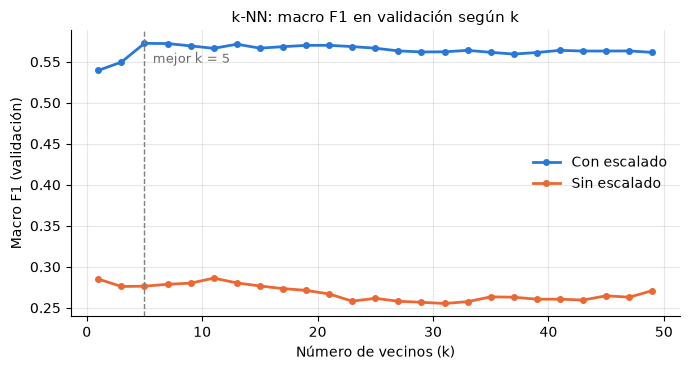

Con escalado: mejor k = 5, macro F1 = 0.573
Sin escalado: mejor k = 11, macro F1 = 0.286


In [18]:
## Macro F1 (val) según k, con y sin escalado
valores_k = list(range(1, 51, 2))
f1_sin, f1_con = [], []
for k in valores_k:
    ## Sin escalado: distancias en las unidades originales
    knn_sin = KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train_c)
    f1_sin.append(f1_score(y_val_c, knn_sin.predict(X_val), average="macro"))
    ## Con escalado: cada predictor con media 0 y DE 1
    knn_con = Pipeline([("escalar", StandardScaler()), ("modelo", KNeighborsClassifier(n_neighbors=k))])
    knn_con.fit(X_train, y_train_c)
    f1_con.append(f1_score(y_val_c, knn_con.predict(X_val), average="macro"))

k_mejor = valores_k[int(np.argmax(f1_con))]
k_mejor_sin = valores_k[int(np.argmax(f1_sin))]

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(valores_k, f1_con, color=AZUL, lw=2, marker="o", ms=4, label="Con escalado")
ax.plot(valores_k, f1_sin, color=NARANJA, lw=2, marker="o", ms=4, label="Sin escalado")
ax.axvline(k_mejor, color="grey", ls="--", lw=1)
ax.annotate(f"mejor k = {k_mejor}", xy=(k_mejor, max(f1_con)), xytext=(6, -14),
            textcoords="offset points", fontsize=9, color="dimgrey")
ax.set_xlabel("Número de vecinos (k)")
ax.set_ylabel("Macro F1 (validación)")
ax.set_title("k-NN: macro F1 en validación según k")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

print(f"Con escalado: mejor k = {k_mejor}, macro F1 = {max(f1_con):.3f}")
print(f"Sin escalado: mejor k = {k_mejor_sin}, macro F1 = {max(f1_sin):.3f}")

In [19]:
## Registrar ambas versiones, cada una con su mejor k en validación
evaluar(f"k-NN sin escalado (k={k_mejor_sin})", KNeighborsClassifier(n_neighbors=k_mejor_sin))
evaluar(f"k-NN con escalado (k={k_mejor})",
        Pipeline([("escalar", StandardScaler()), ("modelo", KNeighborsClassifier(n_neighbors=k_mejor))]));

k-NN sin escalado (k=11): macro F1 (val) = 0.286 | accuracy (val) = 0.289 | ajuste = 0.01 s
k-NN con escalado (k=5): macro F1 (val) = 0.573 | accuracy (val) = 0.573 | ajuste = 0.02 s


**Para recordar.**
- Sin escalado, k-NN mide distancias casi solo en `Population`, que aporta poco: el escalado mejora el macro F1 de forma notable.
- El $k$ se elige en validación, nunca en prueba.
- **Maldición de la dimensionalidad**: con muchos predictores las distancias entre puntos tienden a parecerse y los "vecinos más cercanos" dejan de estar cerca. Con 8 predictores no es un problema; con cientos (texto) sí lo es.
- El costo está en la predicción: cada caso nuevo se compara con todo el entrenamiento.

## 6. Máquinas de vectores de soporte (SVM)

**▶ En vivo.** Una SVM busca el hiperplano que separa las clases con el **mayor margen**. Los casos sobre el margen o dentro de él son los **vectores de soporte** y son los únicos que definen la frontera.
- **`C`** (margen suave): cuánto se penalizan los casos mal clasificados o dentro del margen. Un `C` grande da un margen estrecho y riesgo de sobreajuste.
- **Kernel**: proyecta implícitamente los datos a un espacio donde una frontera lineal basta. Lineal, polinomial (`poly`) o de base radial (`rbf`).
- **`gamma`** (kernels `rbf` y `poly`): alcance de la influencia de cada caso. Un `gamma` grande da fronteras muy locales y riesgo de sobreajuste.
- Con 5 clases, `SVC` entrena $5 \times 4 / 2 = 10$ clasificadores binarios (*one-vs-one*).

### 6.1 Kernels en un ejemplo de juguete

El siguiente ejemplo, ya usado en 2025, está **adaptado del ejemplo de scikit-learn** "Plot classification boundaries with different SVM Kernels" (https://scikit-learn.org/stable/auto_examples/svm/plot_svm_kernels.html, licencia BSD-3-Clause). Dos clases en dos dimensiones; la línea continua es la frontera, las discontinuas son los márgenes y los círculos marcan los vectores de soporte.

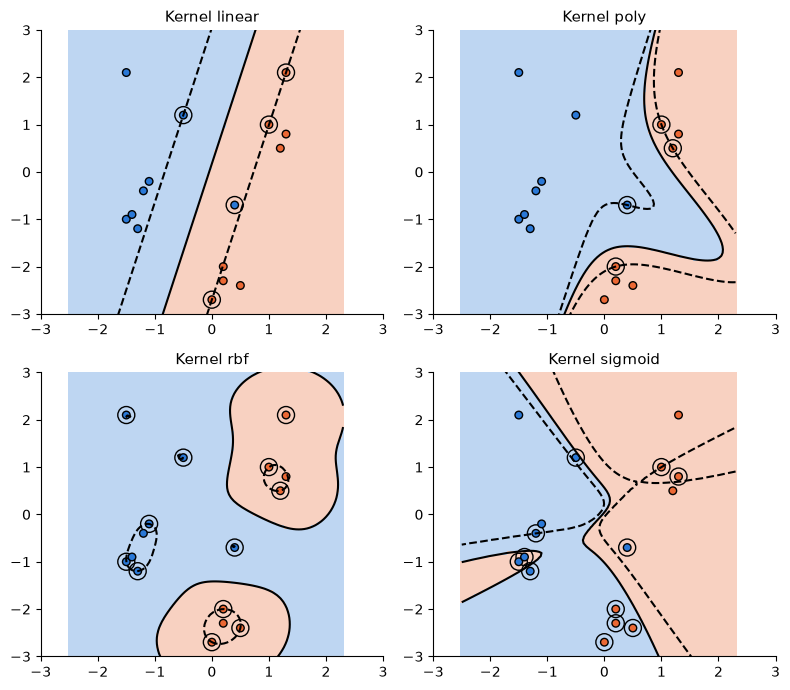

In [20]:
## Datos de juguete del ejemplo de scikit-learn (16 puntos, 2 clases)
X_juguete = np.array([
    [0.4, -0.7], [-1.5, -1.0], [-1.4, -0.9], [-1.3, -1.2], [-1.1, -0.2], [-1.2, -0.4],
    [-0.5, 1.2], [-1.5, 2.1], [1.0, 1.0], [1.3, 0.8], [1.2, 0.5], [0.2, -2.0],
    [0.5, -2.4], [0.2, -2.3], [0.0, -2.7], [1.3, 2.1],
])
y_juguete = np.array([0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1])
cmap_juguete = ListedColormap([AZUL, NARANJA])


def graficar_kernel(kernel, ax):
    ## Ajustar la SVC con el kernel indicado (gamma=2 como en el ejemplo original)
    clf = SVC(kernel=kernel, gamma=2).fit(X_juguete, y_juguete)
    ax.set(xlim=(-3, 3), ylim=(-3, 3))
    comunes = {"estimator": clf, "X": X_juguete, "ax": ax}
    ## Regiones de decisión
    DecisionBoundaryDisplay.from_estimator(
        **comunes, response_method="predict", plot_method="pcolormesh", alpha=0.3, cmap=cmap_juguete
    )
    ## Frontera (0) y márgenes (-1, 1)
    DecisionBoundaryDisplay.from_estimator(
        **comunes, response_method="decision_function", plot_method="contour",
        levels=[-1, 0, 1], colors=["k", "k", "k"], linestyles=["--", "-", "--"],
    )
    ## Vectores de soporte: círculos grandes
    ax.scatter(clf.support_vectors_[:, 0], clf.support_vectors_[:, 1],
               s=150, facecolors="none", edgecolors="k")
    ## Datos coloreados por clase
    ax.scatter(X_juguete[:, 0], X_juguete[:, 1], c=y_juguete, cmap=cmap_juguete, s=30, edgecolors="k")
    ax.set_title(f"Kernel {kernel}")
    ax.grid(False)


fig, axes = plt.subplots(2, 2, figsize=(8, 7))
for kernel, ax in zip(["linear", "poly", "rbf", "sigmoid"], axes.ravel()):
    graficar_kernel(kernel, ax)
plt.tight_layout()
plt.show()

### 6.2 Kernels con California Housing

**▶ En vivo.** El costo de entrenar una SVM crece entre cuadrática y cúbicamente con el número de casos. Para que la demostración sea rápida, comparamos kernels y buscamos hiperparámetros sobre una **submuestra estratificada de 4.000 casos de entrenamiento** (de 14.448). La evaluación sigue siendo sobre todo el conjunto de validación. El escalado va dentro del `Pipeline`.

In [21]:
## Submuestra estratificada de 4.000 casos de entrenamiento (solo para la búsqueda en SVM)
X_sub, _, y_sub, _ = train_test_split(
    X_train, y_train_c, train_size=4000, stratify=y_train_c, random_state=86
)

## Comparar kernels con hiperparámetros por defecto (C=1, gamma='scale')
for kernel in ["linear", "poly", "rbf"]:
    svm_k = Pipeline([("escalar", StandardScaler()), ("modelo", SVC(kernel=kernel))])
    t0 = time.perf_counter()
    svm_k.fit(X_sub, y_sub)
    t_ajuste = time.perf_counter() - t0
    f1_k = f1_score(y_val_c, svm_k.predict(X_val), average="macro")
    print(f"Kernel {kernel:>6}: macro F1 (val) = {f1_k:.3f} | ajuste = {t_ajuste:.2f} s")

Kernel linear: macro F1 (val) = 0.542 | ajuste = 0.40 s


Kernel   poly: macro F1 (val) = 0.480 | ajuste = 0.44 s


Kernel    rbf: macro F1 (val) = 0.553 | ajuste = 0.39 s


### 6.3 Grilla pequeña de `C` × `gamma` (kernel RBF)

Evaluamos 4 × 4 combinaciones en validación, con la misma submuestra.

Grilla de 16 combinaciones: 20.5 s
Mejor combinación: C = 100.0, gamma = 0.1, macro F1 (val) = 0.591


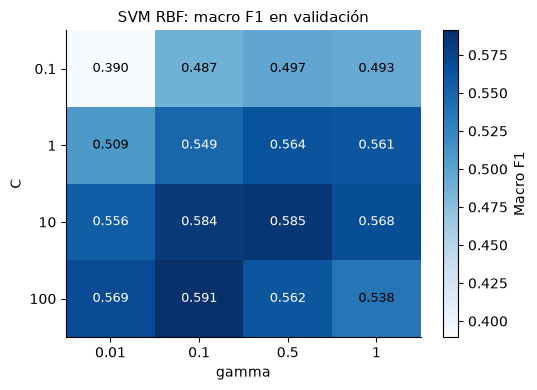

In [22]:
## Grilla C x gamma para el kernel RBF, evaluada en validación
valores_C = [0.1, 1, 10, 100]
valores_gamma = [0.01, 0.1, 0.5, 1]
grilla = pd.DataFrame(index=valores_C, columns=valores_gamma, dtype=float)
t0 = time.perf_counter()
for C in valores_C:
    for gamma in valores_gamma:
        svm_g = Pipeline([("escalar", StandardScaler()), ("modelo", SVC(kernel="rbf", C=C, gamma=gamma))])
        svm_g.fit(X_sub, y_sub)
        grilla.loc[C, gamma] = f1_score(y_val_c, svm_g.predict(X_val), average="macro")
print(f"Grilla de {grilla.size} combinaciones: {time.perf_counter() - t0:.1f} s")

## Mejor combinación
C_mejor, gamma_mejor = grilla.stack().idxmax()
print(f"Mejor combinación: C = {C_mejor}, gamma = {gamma_mejor}, macro F1 (val) = {grilla.loc[C_mejor, gamma_mejor]:.3f}")

## Mapa de calor
fig, ax = plt.subplots(figsize=(5.5, 4))
im = ax.imshow(grilla.values, cmap="Blues", aspect="auto")
ax.set_xticks(range(len(valores_gamma)), labels=valores_gamma)
ax.set_yticks(range(len(valores_C)), labels=valores_C)
ax.set_xlabel("gamma")
ax.set_ylabel("C")
ax.set_title("SVM RBF: macro F1 en validación")
ax.grid(False)
umbral = np.nanmean(grilla.values)
for i in range(len(valores_C)):
    for j in range(len(valores_gamma)):
        v = grilla.values[i, j]
        ax.text(j, i, f"{v:.3f}", ha="center", va="center", fontsize=9,
                color="white" if v > umbral else "black")
fig.colorbar(im, ax=ax, label="Macro F1")
plt.tight_layout()
plt.show()

In [23]:
## SVM RBF con la mejor combinación, ajustada sobre la misma submuestra de 4.000 casos
evaluar("SVM RBF (submuestra 4.000)",
        Pipeline([("escalar", StandardScaler()), ("modelo", SVC(kernel="rbf", C=C_mejor, gamma=gamma_mejor))]),
        X_tr=X_sub, y_tr=y_sub);

SVM RBF (submuestra 4.000): macro F1 (val) = 0.591 | accuracy (val) = 0.593 | ajuste = 0.73 s


**Para recordar.**
- El kernel RBF captura relaciones no lineales que el kernel lineal no ve.
- `C` y `gamma` interactúan: un `C` muy bajo subajusta (fila superior) y valores altos de ambos sobreajustan (esquina inferior derecha del mapa).
- El mejor valor quedó en el borde de la grilla (`C = 100`): en un ajuste real convendría ampliarla en esa dirección.
- La SVM exige escalado y es costosa con muchos casos; en la práctica se usa una submuestra o se cambia de modelo.
- Ajustada con el conjunto de entrenamiento completo rendiría algo mejor, pero tardaría bastante más. Queda en desventaja en la comparación de la sección 10.

## 7. Redes neuronales: perceptrón multicapa (MLP)

Un **perceptrón multicapa** encadena capas de neuronas: cada neurona calcula una suma ponderada de sus entradas y le aplica una función de activación no lineal (ReLU por defecto). Los pesos se aprenden con **retropropagación** (*backpropagation*): el gradiente del error se propaga desde la salida hacia atrás para actualizar cada peso.

Usamos dos capas ocultas (64 y 32 neuronas), escalado previo (imprescindible) y `early_stopping=True`: scikit-learn reserva internamente el 10% del entrenamiento y detiene el ajuste cuando la exactitud en esa porción deja de mejorar durante 10 épocas.

*Puente a S13:* los modelos de lenguaje como BERT son redes neuronales con la misma lógica de pesos y retropropagación, pero con muchas más capas y parámetros.

In [24]:
## MLP con dos capas ocultas y parada temprana (early stopping)
mlp = Pipeline([
    ("escalar", StandardScaler()),
    ("modelo", MLPClassifier(hidden_layer_sizes=(64, 32), early_stopping=True,
                             max_iter=500, random_state=86)),
])
evaluar("MLP (64, 32)", mlp)
print(f"Épocas hasta la parada temprana: {mlp.named_steps['modelo'].n_iter_}")

MLP (64, 32): macro F1 (val) = 0.622 | accuracy (val) = 0.624 | ajuste = 5.09 s
Épocas hasta la parada temprana: 102


**Para recordar.**
- El MLP aprende relaciones no lineales sin elegir un kernel, pero tiene muchos hiperparámetros (capas, neuronas, tasa de aprendizaje, regularización `alpha`).
- Requiere escalado y es poco interpretable.
- En datos tabulares de tamaño moderado, los modelos basados en árboles (secciones 8 y 9) suelen rendir igual o mejor con menos ajuste.

## 8. Random forest

Un **random forest** promedia muchos árboles de decisión, cada uno ajustado sobre una muestra *bootstrap* del entrenamiento (*bagging*) y considerando en cada división solo un subconjunto aleatorio de predictores (`max_features="sqrt"` por defecto). Así los árboles son menos parecidos entre sí y su promedio tiene menos varianza.

**Error OOB** (*out-of-bag*): cada árbol deja fuera alrededor de un tercio de los casos de entrenamiento. Predecir cada caso solo con los árboles que no lo vieron da una estimación del error sin un conjunto de validación aparte. Aquí pedimos que el puntaje OOB sea el macro F1.

No requiere escalado: los árboles dividen por umbrales, que no cambian con transformaciones monótonas.

In [25]:
## Puntaje OOB con macro F1 (por defecto sería accuracy)
def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, average="macro")


## Random forest con 100 y 500 árboles (n_jobs=-1 usa todos los núcleos)
for n in [100, 500]:
    rf = evaluar(f"Random forest ({n} árboles)",
                 RandomForestClassifier(n_estimators=n, oob_score=macro_f1, n_jobs=-1, random_state=86))
    print(f"   macro F1 OOB = {rf.oob_score_:.3f}")

Random forest (100 árboles): macro F1 (val) = 0.664 | accuracy (val) = 0.667 | ajuste = 0.39 s
   macro F1 OOB = 0.676


Random forest (500 árboles): macro F1 (val) = 0.668 | accuracy (val) = 0.671 | ajuste = 2.03 s
   macro F1 OOB = 0.689


### 8.1 Más árboles no aumentan el sobreajuste

Breiman (2001) muestra que el error de generalización de un random forest **converge** a medida que se agregan árboles: más árboles estabilizan el resultado y cuestan más tiempo, pero no sobreajustan. Lo comprobamos agregando árboles a un mismo bosque (`warm_start=True`) de 10 a 500.

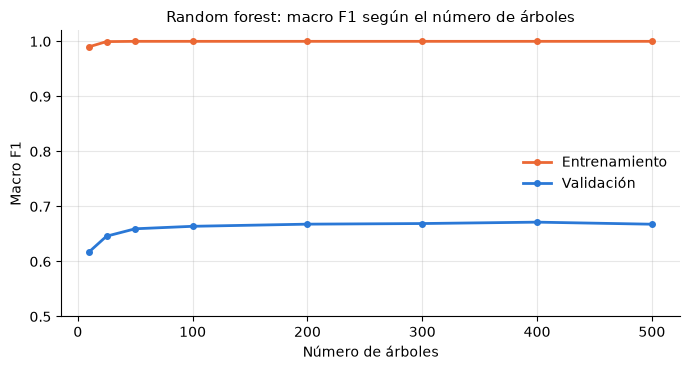

Macro F1 (val): {10: np.float64(0.618), 25: np.float64(0.646), 50: np.float64(0.659), 100: np.float64(0.664), 200: np.float64(0.668), 300: np.float64(0.669), 400: np.float64(0.671), 500: np.float64(0.668)}


In [26]:
## Agregar árboles progresivamente al mismo bosque y medir el macro F1
n_arboles = [10, 25, 50, 100, 200, 300, 400, 500]
rf_ws = RandomForestClassifier(warm_start=True, n_jobs=-1, random_state=86)
f1_tr_ws, f1_val_ws = [], []
for n in n_arboles:
    rf_ws.set_params(n_estimators=n)
    rf_ws.fit(X_train, y_train_c)
    f1_tr_ws.append(f1_score(y_train_c, rf_ws.predict(X_train), average="macro"))
    f1_val_ws.append(f1_score(y_val_c, rf_ws.predict(X_val), average="macro"))

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(n_arboles, f1_tr_ws, color=NARANJA, lw=2, marker="o", ms=4, label="Entrenamiento")
ax.plot(n_arboles, f1_val_ws, color=AZUL, lw=2, marker="o", ms=4, label="Validación")
ax.set_xlabel("Número de árboles")
ax.set_ylabel("Macro F1")
ax.set_ylim(0.5, 1.02)
ax.set_title("Random forest: macro F1 según el número de árboles")
ax.legend(frameon=False, loc="center right")
plt.tight_layout()
plt.show()
print("Macro F1 (val):", dict(zip(n_arboles, np.round(f1_val_ws, 3))))

La brecha entre entrenamiento (≈ 1) y validación existe desde el principio y no crece con el número de árboles. Esa brecha viene de la **profundidad de cada árbol**: por defecto los árboles crecen hasta que sus hojas son puras. Los hiperparámetros que controlan el sobreajuste son `max_depth` y `min_samples_leaf`.

In [27]:
## Profundidad y tamaño mínimo de hoja: brecha entre entrenamiento y validación (100 árboles)
configuraciones = [
    {"max_depth": None, "min_samples_leaf": 1},
    {"max_depth": None, "min_samples_leaf": 5},
    {"max_depth": None, "min_samples_leaf": 20},
    {"max_depth": 10, "min_samples_leaf": 1},
    {"max_depth": 4, "min_samples_leaf": 1},
]
filas = []
for cfg in configuraciones:
    rf_cfg = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=86, **cfg).fit(X_train, y_train_c)
    f1_tr = f1_score(y_train_c, rf_cfg.predict(X_train), average="macro")
    f1_v = f1_score(y_val_c, rf_cfg.predict(X_val), average="macro")
    filas.append({"max_depth": str(cfg["max_depth"]), "min_samples_leaf": cfg["min_samples_leaf"], "Macro F1 (train)": f1_tr, "Macro F1 (val)": f1_v, "Brecha": f1_tr - f1_v})
pd.DataFrame(filas).round(3)

,max_depth,min_samples_leaf,Macro F1 (train),Macro F1 (val),Brecha
0,None,1,1.000,0.664,0.336
1,None,5,0.892,0.663,0.229
2,None,20,0.737,0.635,0.102
3,10,1,0.797,0.634,0.162
4,4,1,0.537,0.518,0.019


### 8.2 Importancia de variables: impureza vs permutación

- **Por impureza** (`feature_importances_`): cuánto reduce cada predictor la impureza de Gini en los árboles. Se calcula en entrenamiento y favorece a los predictores continuos con muchos valores posibles.
- **Por permutación**: cuánto cae el macro F1 **en validación** al desordenar al azar un predictor. Mide lo que el modelo usa para generalizar. Repetimos cada permutación 5 veces.

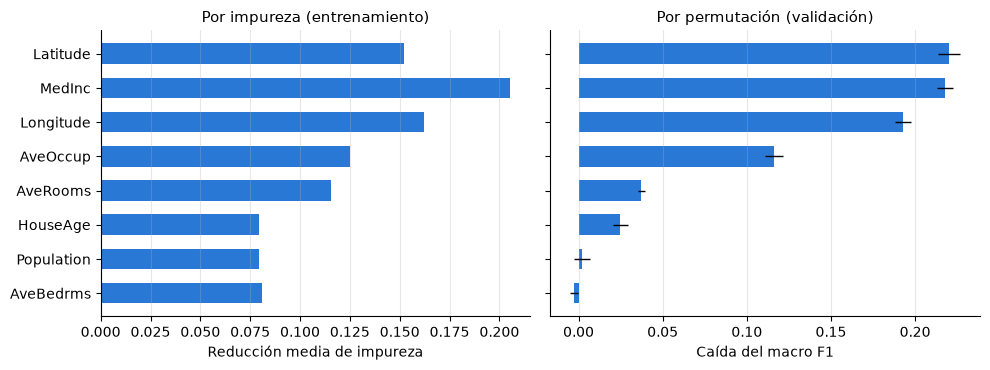

In [28]:
## Importancia por impureza y por permutación (en validación) del bosque de 500 árboles
rf_500 = modelos["Random forest (500 árboles)"]
imp_impureza = pd.Series(rf_500.feature_importances_, index=X.columns)
perm = permutation_importance(rf_500, X_val, y_val_c, scoring="f1_macro", n_repeats=5, random_state=86)
imp_perm = pd.Series(perm.importances_mean, index=X.columns)

orden = imp_perm.sort_values().index
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
axes[0].barh(orden, imp_impureza[orden], color=AZUL, height=0.6)
axes[0].set_title("Por impureza (entrenamiento)")
axes[0].set_xlabel("Reducción media de impureza")
axes[1].barh(orden, imp_perm[orden], xerr=pd.Series(perm.importances_std, index=X.columns)[orden],
             color=AZUL, height=0.6, error_kw={"lw": 1})
axes[1].set_title("Por permutación (validación)")
axes[1].set_xlabel("Caída del macro F1")
for ax in axes:
    ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**Para recordar.**
- Random forest es un excelente modelo por defecto en datos tabulares: poco ajuste, sin escalado, con OOB gratis.
- Agregar árboles no produce sobreajuste; lo que lo controla es la profundidad y el tamaño de las hojas.
- Para interpretar, prefiera la importancia por permutación en validación. Aquí `Population` y `AveBedrms` reciben una importancia por impureza similar a la de `HouseAge`, pero desordenarlas casi no cambia el macro F1. Ninguna de las dos es un efecto causal, y ambas reparten la importancia entre predictores correlacionados (`Latitude` y `Longitude`).
- Los ensambles se tratan en detalle en S10.

## 9. XGBoost

**XGBoost** (Chen y Guestrin, 2016) es un ensamble de árboles construido **secuencialmente**: cada árbol nuevo se ajusta a los gradientes del error (en el caso cuadrático, los residuos) del ensamble anterior. No es una red neuronal. Sus piezas principales:
- **Función objetivo regularizada**: penaliza el número de hojas y el tamaño de sus pesos (`gamma`, `reg_lambda`, `reg_alpha`). Reduce el sobreajuste, pero no lo elimina.
- **`learning_rate`**: encoge la contribución de cada árbol. Valores bajos requieren más árboles y suelen generalizar mejor.
- **`max_depth`**: profundidad de cada árbol (por defecto, 6).
- **Parada temprana** (*early stopping*): se detiene cuando la pérdida en un conjunto de evaluación no mejora durante `early_stopping_rounds` iteraciones.

Usamos validación como conjunto de evaluación para la parada temprana. Esto vuelve un poco optimista el macro F1 de validación de XGBoost; en S9 y S10 separaremos un conjunto interno para este fin.

In [29]:
## XGBoost con parada temprana sobre validación (pérdida logarítmica multiclase)
xgb_clf = xgb.XGBClassifier(
    n_estimators=2000,            ## máximo de árboles; la parada temprana decide cuántos usar
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,                ## fracción de casos por árbol
    colsample_bytree=0.8,         ## fracción de predictores por árbol
    early_stopping_rounds=50,
    eval_metric="mlogloss",
    tree_method="hist",
    n_jobs=-1,
    random_state=86,
)
evaluar("XGBoost", xgb_clf, eval_set=[(X_train, y_train_c), (X_val, y_val_c)], verbose=False)
print(f"Mejor iteración: {xgb_clf.best_iteration} | mlogloss (val) en esa iteración: {xgb_clf.best_score:.4f}")

XGBoost: macro F1 (val) = 0.696 | accuracy (val) = 0.699 | ajuste = 8.17 s
Mejor iteración: 566 | mlogloss (val) en esa iteración: 0.7352


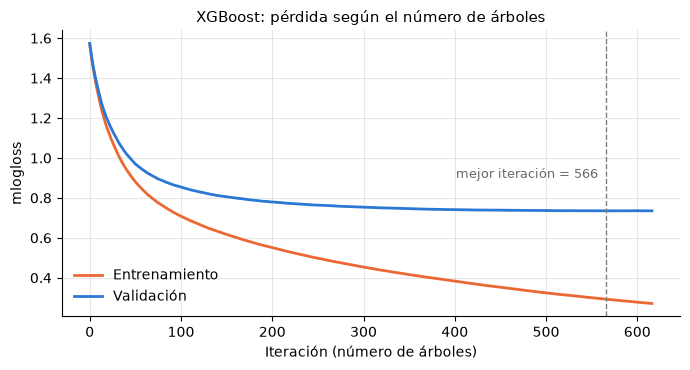

In [30]:
## Curvas de pérdida en entrenamiento y validación
historial = xgb_clf.evals_result()
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(historial["validation_0"]["mlogloss"], color=NARANJA, lw=2, label="Entrenamiento")
ax.plot(historial["validation_1"]["mlogloss"], color=AZUL, lw=2, label="Validación")
ax.axvline(xgb_clf.best_iteration, color="grey", ls="--", lw=1)
ax.annotate(f"mejor iteración = {xgb_clf.best_iteration}", xy=(xgb_clf.best_iteration, 0.9),
            xytext=(-6, 0), textcoords="offset points", ha="right", fontsize=9, color="dimgrey")
ax.set_xlabel("Iteración (número de árboles)")
ax.set_ylabel("mlogloss")
ax.set_title("XGBoost: pérdida según el número de árboles")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

In [31]:
## learning_rate y max_depth: con una tasa mayor se necesitan muchos menos árboles
filas = []
for lr in [0.3, 0.1]:
    for md_ in [3, 6]:
        m = xgb.XGBClassifier(n_estimators=2000, learning_rate=lr, max_depth=md_, subsample=0.8,
                              colsample_bytree=0.8, early_stopping_rounds=50, eval_metric="mlogloss",
                              tree_method="hist", n_jobs=-1, random_state=86)
        t0 = time.perf_counter()
        m.fit(X_train, y_train_c, eval_set=[(X_val, y_val_c)], verbose=False)
        filas.append({"learning_rate": lr, "max_depth": md_, "Mejor iteración": m.best_iteration,
                      "Macro F1 (val)": f1_score(y_val_c, m.predict(X_val), average="macro"),
                      "Tiempo (s)": time.perf_counter() - t0})
pd.DataFrame(filas).round(3)

,learning_rate,max_depth,Mejor iteración,Macro F1 (val),Tiempo (s)
0,0.3,3,431,0.683,3.413
1,0.3,6,79,0.685,1.629
2,0.1,3,1095,0.682,8.143
3,0.1,6,269,0.697,3.962


**Para recordar.**
- XGBoost suele ser el modelo más fuerte en datos tabulares, a cambio de más hiperparámetros.
- La parada temprana elige el número de árboles; tras ella, `predict` usa automáticamente la mejor iteración.
- `learning_rate` y el número de árboles se compensan: tasas bajas requieren más árboles.
- La regularización reduce el sobreajuste, pero no lo elimina: la curva de entrenamiento sigue bajando cuando la de validación ya se estancó.

## 10. Comparación de modelos y evaluación final en prueba

**▶ En vivo.** Reunimos el macro F1 en validación y el tiempo de ajuste de todos los modelos registrados. Los tiempos dependen del computador y son solo orientativos.

In [32]:
## Tabla comparativa ordenada por macro F1 en validación
comparacion = (pd.DataFrame(resultados).T
               .sort_values("Macro F1 (val)", ascending=False)
               .rename_axis("Modelo"))
comparacion.round(3)

,Macro F1 (val),Accuracy (val),Tiempo de ajuste (s)
Modelo,,,
XGBoost,0.696,0.699,8.167
Random forest (500 árboles),0.668,0.671,2.028
Random forest (100 árboles),0.664,0.667,0.393
"MLP (64, 32)",0.622,0.624,5.091
SVM RBF (submuestra 4.000),0.591,0.593,0.731
k-NN con escalado (k=5),0.573,0.573,0.018
Regresión logística,0.525,0.532,0.055
Naive Bayes (gaussiano),0.330,0.386,0.004
k-NN sin escalado (k=11),0.286,0.289,0.009


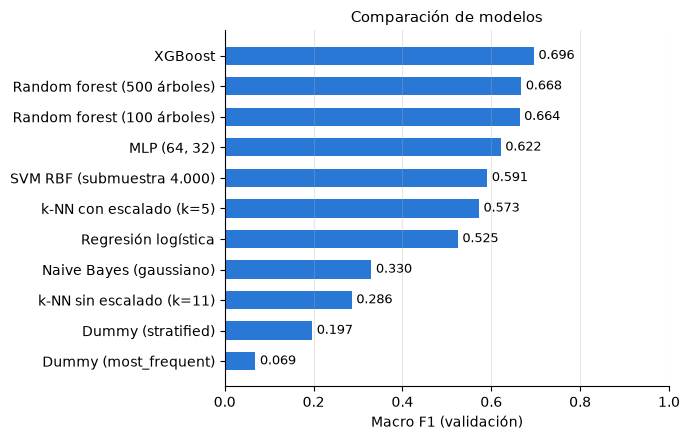

In [33]:
## Gráfico de barras del macro F1 en validación
orden_cmp = comparacion["Macro F1 (val)"].sort_values()
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(orden_cmp.index, orden_cmp.values, color=AZUL, height=0.6)
for i, v in enumerate(orden_cmp.values):
    ax.text(v + 0.01, i, f"{v:.3f}", va="center", fontsize=9)
ax.set_xlim(0, 1)
ax.set_xlabel("Macro F1 (validación)")
ax.set_title("Comparación de modelos")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

### 10.1 Evaluación final en prueba: una sola vez

**▶ En vivo.** Elegimos el modelo con mejor macro F1 en validación y lo evaluamos **una única vez** en prueba.

¿Por qué una sola vez? Todas las decisiones anteriores (el $k$ de k-NN, `C` y `gamma`, la parada temprana, la elección del modelo) se tomaron mirando validación. Por eso el macro F1 de validación del modelo ganador es **optimista**. Si también eligiéramos mirando prueba, ese conjunto se convertiría en otra validación y perderíamos la única estimación honesta del desempeño con datos nuevos. En el desafío, el conjunto de prueba lo tiene el equipo docente por la misma razón.

In [34]:
## Mejor modelo según validación, evaluado una sola vez en prueba
nombre_mejor = comparacion["Macro F1 (val)"].idxmax()
mejor = modelos[nombre_mejor]
pred_test = mejor.predict(X_test)
print(f"Modelo elegido: {nombre_mejor}")
print(f"Macro F1 (val)    = {comparacion.loc[nombre_mejor, 'Macro F1 (val)']:.3f}")
print(f"Macro F1 (prueba) = {f1_score(y_test_c, pred_test, average='macro'):.3f}\n")
print(classification_report(y_test_c, pred_test, target_names=etiquetas, digits=3))

Modelo elegido: XGBoost
Macro F1 (val)    = 0.696
Macro F1 (prueba) = 0.703

              precision    recall  f1-score   support

         Low      0.829     0.833     0.831       634
  Medium-Low      0.617     0.650     0.633       602
      Medium      0.589     0.612     0.600       608
 Medium-High      0.647     0.625     0.636       613
        High      0.840     0.790     0.815       639

    accuracy                          0.704      3096
   macro avg      0.704     0.702     0.703      3096
weighted avg      0.707     0.704     0.705      3096



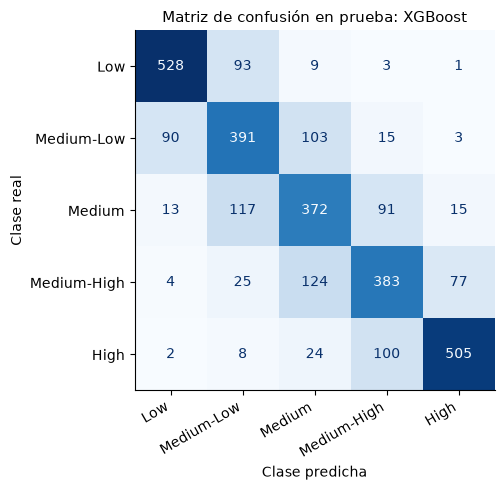

In [35]:
## Matriz de confusión en prueba (conteos)
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test_c, pred_test, display_labels=etiquetas, cmap="Blues", colorbar=False, ax=ax
)
ax.set_title(f"Matriz de confusión en prueba: {nombre_mejor}")
ax.set_xlabel("Clase predicha")
ax.set_ylabel("Clase real")
ax.grid(False)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

**Para recordar.**
- La mayoría de los errores ocurre entre **clases adyacentes** (`Medium` con `Medium-Low` o `Medium-High`): el orden de las clases está implícito en los datos aunque el F1 no lo use.
- Las clases extremas (`Low`, `High`) suelen ser las más fáciles; las intermedias, las más difíciles.
- Validación sirve para elegir; prueba, para informar.

## 11. Fronteras de decisión con dos predictores

**▶ En vivo.** Para ver *cómo* decide cada modelo, ajustamos cuatro modelos usando solo `Longitude` y `Latitude`, sobre la misma submuestra de 4.000 casos de entrenamiento de la sección 6 (por costo del SVM y para que la comparación sea justa). El color de fondo es la clase predicha en cada punto del plano, del más claro (`Low`) al más oscuro (`High`); los puntos son 1.500 casos de validación. El resultado es, literalmente, un mapa de California.

Hiperparámetros: regresión logística por defecto; k-NN con $k = 15$; SVM RBF con `C = 10` y `gamma = 1`; random forest con 200 árboles y `min_samples_leaf = 5`. Son valores razonables, no ajustados.

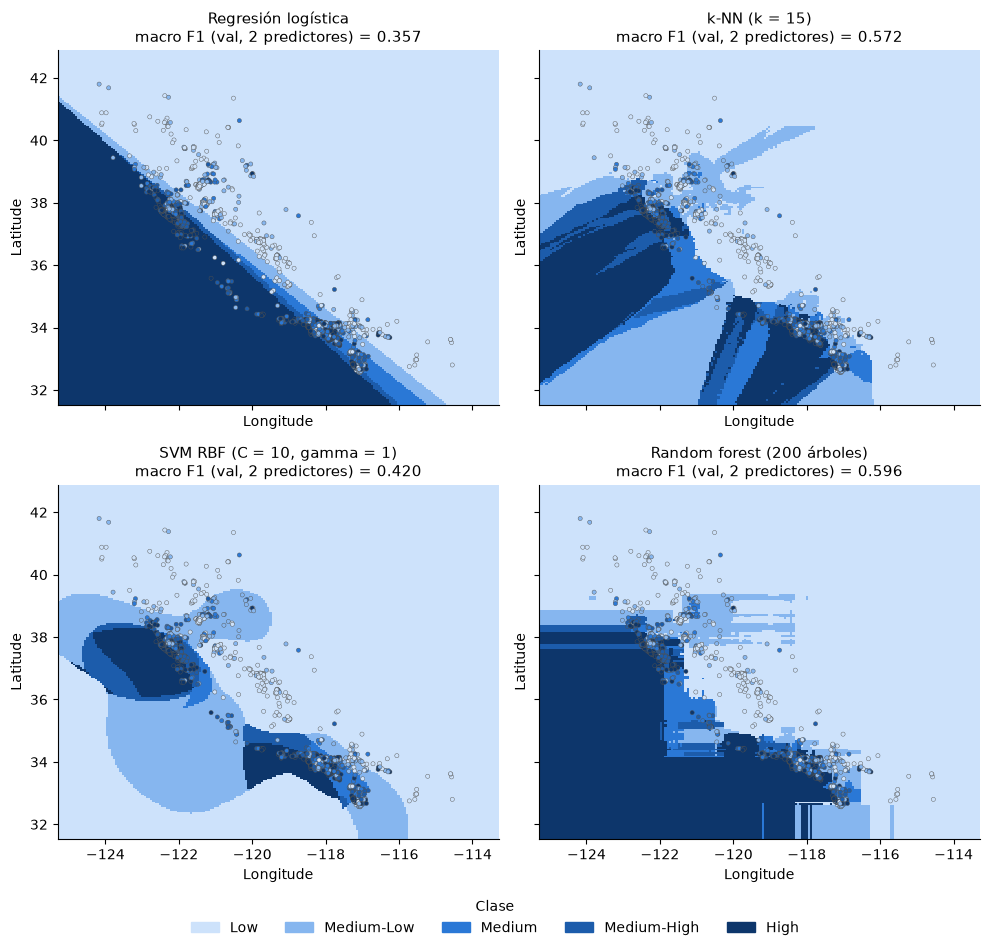

In [36]:
## Dos predictores espaciales y submuestras para ajustar y graficar
vars_2d = ["Longitude", "Latitude"]
X_sub_2d = X_sub[vars_2d]
X_val_2d = X_val[vars_2d]
idx_graf = np.random.default_rng(86).choice(len(X_val_2d), size=1500, replace=False)

modelos_2d = {
    "Regresión logística": Pipeline([("escalar", StandardScaler()), ("modelo", LogisticRegression(max_iter=1000))]),
    "k-NN (k = 15)": Pipeline([("escalar", StandardScaler()), ("modelo", KNeighborsClassifier(n_neighbors=15))]),
    "SVM RBF (C = 10, gamma = 1)": Pipeline([("escalar", StandardScaler()), ("modelo", SVC(kernel="rbf", C=10, gamma=1))]),
    "Random forest (200 árboles)": RandomForestClassifier(n_estimators=200, min_samples_leaf=5, n_jobs=-1, random_state=86),
}
cmap_clases = ListedColormap(RAMPA_CLASES)
## Nota de versión: multiclass_colors existe desde scikit-learn 1.7; en versiones anteriores
## (como la de Colab) el color de cada clase se fija con cmap
if "multiclass_colors" in inspect.signature(DecisionBoundaryDisplay.from_estimator).parameters:
    colores_clases = {"multiclass_colors": RAMPA_CLASES}
else:
    colores_clases = {"cmap": cmap_clases, "vmin": 0, "vmax": 4}

fig, axes = plt.subplots(2, 2, figsize=(10, 9.5), sharex=True, sharey=True)
for (nombre, modelo), ax in zip(modelos_2d.items(), axes.ravel()):
    modelo.fit(X_sub_2d, y_sub)
    f1_2d = f1_score(y_val_c, modelo.predict(X_val_2d), average="macro")
    ## Fondo: clase predicha en una grilla de 200 x 200 puntos (un color fijo por clase)
    DecisionBoundaryDisplay.from_estimator(
        modelo, X_sub_2d, response_method="predict", plot_method="pcolormesh",
        grid_resolution=200, ax=ax, **colores_clases,
        xlabel="Longitude", ylabel="Latitude",
    )
    ## Puntos de validación con su clase real
    ax.scatter(X_val_2d.iloc[idx_graf, 0], X_val_2d.iloc[idx_graf, 1], c=y_val_c[idx_graf],
               cmap=cmap_clases, vmin=0, vmax=4, s=9, edgecolors="#52514e", linewidths=0.3)
    ax.set_title(f"{nombre}\nmacro F1 (val, 2 predictores) = {f1_2d:.3f}")
    ax.grid(False)

fig.legend(handles=[Patch(color=c, label=e) for c, e in zip(RAMPA_CLASES, etiquetas)],
           loc="lower center", ncol=5, frameon=False, title="Clase")
plt.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

**Para recordar.**
- **Regresión logística**: fronteras lineales (aquí, bandas paralelas). No puede representar la costa ni las áreas metropolitanas.
- **k-NN**: fronteras irregulares que siguen la densidad local de los datos.
- **SVM RBF**: fronteras suaves y curvas; `gamma` controla cuán locales son.
- **Random forest**: fronteras en escalera, paralelas a los ejes, porque cada árbol divide por umbrales de una variable.
- La ubicación sola ya separa bastante bien las clases: el valor de la vivienda tiene un fuerte componente espacial.
- Fuera de la nube de puntos (el océano, el desierto) cada modelo extrapola a su manera: esas regiones del gráfico no tienen interpretación sustantiva.

## 12. Ejercicios

**(a) El mejor modelo con a lo sumo 5 predictores.** Esta es la regla del desafío de predicción. Una estrategia simple es la **selección hacia adelante** (*forward selection*) evaluada en validación: se parte sin predictores, en cada paso se agrega el que más mejora el macro F1 en validación y se detiene en 5. La función de abajo la implementa; la ejecutamos con la regresión logística como ejemplo, porque es rápida.
1. Aplíquela a un modelo más fuerte (random forest con 100 árboles, o XGBoost con `n_estimators` fijo y sin parada temprana). Calcule cuántos ajustes requiere antes de ejecutarla.
2. Compare el macro F1 con 5 predictores con el obtenido con los 8.
3. ¿Coinciden los predictores elegidos con la importancia por permutación de la sección 8.2? ¿Qué cautela merece haber seleccionado predictores mirando validación?

In [37]:
def seleccion_hacia_adelante(crear_modelo, max_vars=5, candidatas=None):
    ## Selección hacia adelante: agrega en cada paso el predictor que más mejora el macro F1 en validación
    candidatas = list(X_train.columns) if candidatas is None else list(candidatas)
    elegidas, historial = [], []
    while len(elegidas) < max_vars and candidatas:
        puntajes = {}
        for var in candidatas:
            cols = elegidas + [var]
            m = crear_modelo().fit(X_train[cols], y_train_c)
            puntajes[var] = f1_score(y_val_c, m.predict(X_val[cols]), average="macro")
        mejor_var = max(puntajes, key=puntajes.get)
        elegidas.append(mejor_var)
        candidatas.remove(mejor_var)
        historial.append({"Paso": len(elegidas), "Predictor agregado": mejor_var,
                          "Macro F1 (val)": round(puntajes[mejor_var], 3)})
    return elegidas, pd.DataFrame(historial)


## Ejemplo con regresión logística (8 + 7 + 6 + 5 + 4 = 30 ajustes)
def crear_reg_log():
    return Pipeline([("escalar", StandardScaler()), ("modelo", LogisticRegression(max_iter=1000))])


elegidas_rl, historial_rl = seleccion_hacia_adelante(crear_reg_log, max_vars=5)
historial_rl

,Paso,Predictor agregado,Macro F1 (val)
0,1,MedInc,0.390
1,2,AveOccup,0.425
2,3,Latitude,0.451
3,4,Longitude,0.515
4,5,Population,0.522


**(b) Interpretar dos odds ratios de la regresión logística.** Con la tabla de la sección 3.1, escriba una oración para cada uno de dos predictores (distintos de `MedInc`) con el formato: "Un aumento de una DE en *X* (≈ *valor* en unidades originales) multiplica las odds de `High` frente a `Low` por *OR*, manteniendo constantes los demás predictores". Luego:
1. Convierta uno de ellos a unidades originales: el odds ratio por unidad original es $\exp\big((\beta_{\text{High},j} - \beta_{\text{Low},j}) / \text{DE}_j\big)$.
2. Discuta si el signo es sustantivamente plausible o si puede deberse a la correlación con otro predictor.

**(c) k-NN con y sin escalado en su propio subconjunto de predictores.** Elija entre 2 y 4 predictores (por ejemplo, uno con escala grande como `Population` y otro con escala pequeña como `MedInc`). Repita la curva de la sección 5 con y sin `StandardScaler`. ¿Cuándo importa más el escalado? Pista: compare las desviaciones estándar de sus predictores con `X_train[mis_vars].std()`.

In [38]:
## Plantilla para el ejercicio (c): descomente y complete
# mis_vars = ["MedInc", "Population"]
# for k in [5, 15, 31]:
#     sin = KNeighborsClassifier(n_neighbors=k).fit(X_train[mis_vars], y_train_c)
#     con = Pipeline([("escalar", StandardScaler()), ("modelo", KNeighborsClassifier(n_neighbors=k))])
#     con.fit(X_train[mis_vars], y_train_c)
#     print(k,
#           round(f1_score(y_val_c, sin.predict(X_val[mis_vars]), average="macro"), 3),
#           round(f1_score(y_val_c, con.predict(X_val[mis_vars]), average="macro"), 3))

**Para recordar (síntesis de la sesión).**
- Fije siempre una línea base y una métrica acorde al problema (aquí, macro F1).
- Los modelos lineales e interpretables (regresión logística) y los de vecindad (k-NN) o margen (SVM) requieren escalado; los árboles no.
- Los ensambles de árboles (random forest, XGBoost) suelen ganar en datos tabulares; su costo es la interpretabilidad.
- Validación para elegir; prueba, una vez, para informar.
- **Próxima sesión (S9):** pipelines, validación cruzada y fuga de información.